# Optimizing parameters for the Zener function used to describe rock stress

In [ ]:
!pip install pygad

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pygad
from tqdm import tqdm

In [2]:
Np = 21  # Number of periods Tp
Nsamp = 1000  # Number of samples per period

Rsig = [+1, 0, -1, +1, 0, -1, +1, 0, -1,
        +1, +1, 0, 0, -1, -1, +1, +1, 0, 0, -1, -1]

t0 = 0.0

def fSig(x, x1, Rs):
    return Rs * (x - x1)

def fEpsNL(Sig, EmNL, Alpha):
    return Sig / (EmNL * (1 + Alpha * Sig))

def fEps(x, x1, x2, Rs, Em, Tau_s, Tau_e):
    return (Rs / Em) * (
        (x2 - x1) + (Tau_s - Tau_e) * (np.exp(x2 / Tau_e) - np.exp(x1 / Tau_e)) * np.exp(-x / Tau_e)
    )

def fEps0(x, Rs, Em, Tau_s, Tau_e):
    return fEps(x, t0, x, Rs, Em, Tau_s, Tau_e)

def fEpsVE(x, i, Rsig, R, Tp, Em, Tau_s, Tau_e):
    epsVE = fEps0(x - (i - 1) * Tp, Rsig[i - 1] * R, Em, Tau_s, Tau_e)
    for k in range(1, i):
        epsVE += fEps(x, (k - 1) * Tp, k * Tp, Rsig[k - 1] * R, Em, Tau_s, Tau_e)
    return epsVE

In [3]:
df_target = pd.read_csv('ZenerModel.dat', delim_whitespace=True)
df_target['time'] = pd.to_numeric(df_target['time'], errors='coerce')
df_target = df_target.dropna()
df_target_sorted = df_target.sort_values('time')

print(df_target.head())
print(df_target.dtypes)
print(df_target.isna().sum())

   time  Stress  StrainNonLinEl  StrainViscEl  TotStrain
0   0.1   0.001        0.004985      0.000500   0.005486
1   0.2   0.002        0.009940      0.001002   0.010942
2   0.3   0.003        0.014866      0.001504   0.016371
3   0.4   0.004        0.019763      0.002008   0.021771
4   0.5   0.005        0.024631      0.002512   0.027143
time              float64
Stress            float64
StrainNonLinEl    float64
StrainViscEl      float64
TotStrain         float64
dtype: object
time              0
Stress            0
StrainNonLinEl    0
StrainViscEl      0
TotStrain         0
dtype: int64


/tmp/ipykernel_598432/3236189177.py:1: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df_target = pd.read_csv('ZenerModel.dat', delim_whitespace=True)


In [4]:
dt = df_target.iloc[1].time - df_target.iloc[0].time
Tp = dt * Nsamp
dt, Tp

(0.1, 100.0)

In [5]:
def compute_all(params):
    Em, Tau_e, Tau_s, EmNL, Alpha, Sig0 = params
    
    t = 0.0
    FvalSig = 0.0
    
    R = Sig0 / Tp
    # dt = Tp / Nsamp
    
    data = []

    for i in range(1, Np + 1):
        for j in range(Nsamp):
            t += dt
            valSig = FvalSig + fSig(t, (i - 1) * Tp, Rsig[i - 1] * R)
            valEpsNL = fEpsNL(valSig, EmNL, Alpha)
            valEpsVE = fEpsVE(t, i, Rsig, R, Tp, Em, Tau_s, Tau_e)
            
            data.append({
                'time': t,
                'Stress': valSig,
                'StrainNonLinEl': valEpsNL,
                'StrainViscEl': valEpsVE,
                'TotStrain': valEpsNL + valEpsVE,
            })
        
        FvalSig = valSig
    
    return pd.DataFrame(data)

In [16]:
def fitness_func(ga_instance, solution, solution_idx):
    df = compute_all(solution)
    df_sorted = df.sort_values('time')

    merged = pd.merge_asof(
        df_sorted, 
        df_target_sorted, 
        on='time', 
        direction='nearest', 
        tolerance=1e-8,
        suffixes=('_model', '_target')
    )

    match_ratio = len(merged) / len(df_target)
    if match_ratio < 0.95:
        return -1e9

    cols = ['Stress', 'StrainNonLinEl', 'StrainViscEl', 'TotStrain']

    error = 0.0
    for col in cols:
        diff = merged[f'{col}_model'] - merged[f'{col}_target']
        error += np.sum(diff ** 2)

    return -error

  0%|                                                                                                       | 0/20 [00:00<?, ?it/s]/home/ondra/.local/lib/python3.10/site-packages/pygad/pygad.py:1136: UserWarning: Use the 'save_best_solutions' parameter with caution as it may cause memory overflow when either the number of generations or number of genes is large.
  warnings.warn("Use the 'save_best_solutions' parameter with caution as it may cause memory overflow when either the number of generations or number of genes is large.")
100%|█████████████████████████████████████████████████████████████████████████| 20/20 [16:54<00:00, 46.93s/it, fitness=-1.7257e+03]No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


[ 1.17605835 57.26468573 40.04445637  0.15940238  4.28730042  1.20809913] -1642.6642300882118


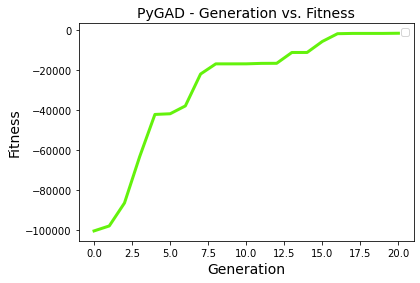

100%|█████████████████████████████████████████████████████████████████████████| 20/20 [17:32<00:00, 52.60s/it, fitness=-1.7257e+03]


In [21]:
num_generations = 20

def on_generation(ga):
    pbar.set_postfix(fitness=f'{ga.last_generation_fitness[0]:.4e}')
    pbar.update(1)

with tqdm(total=num_generations) as pbar:
    ga = pygad.GA(
        num_generations=num_generations,
        num_parents_mating=5,
        fitness_func=fitness_func,
        sol_per_pop=20,
        num_genes=6,
        mutation_percent_genes=30,
        gene_space=[
            {'low': 0.1, 'high': 10.0},  # Em
            {'low': 10, 'high': 100},    # Tau_e
            {'low': 10, 'high': 100},    # Tau_s
            {'low': 0.01, 'high': 3},    # EmNL
            {'low': 0.1, 'high': 10},    # Alpha
            {'low': 0.1, 'high': 10},    # Sig0
        ],
        on_generation=lambda ga: on_generation(ga),
        save_best_solutions=True,
    )
    
    ga.run()
    solution, solution_fitness, _ = ga.best_solution()
    print(solution, solution_fitness)
    
    ga.plot_fitness()

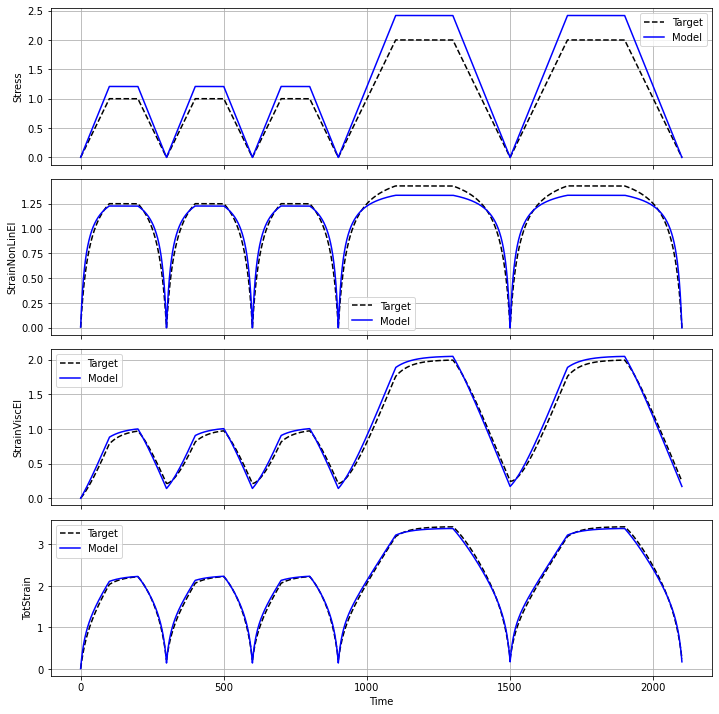

In [22]:
df = compute_all(solution)
df_sorted = df.sort_values('time')

merged = pd.merge_asof(
    df_sorted, 
    df_target_sorted, 
    on='time', 
    direction='nearest', 
    tolerance=1e-8,
    suffixes=('_model', '_target'),
)

cols = ['Stress', 'StrainNonLinEl', 'StrainViscEl', 'TotStrain']
fig, axes = plt.subplots(len(cols), 1, figsize=(10, 2.5 * len(cols)), sharex=True)

for i, col in enumerate(cols):
    ax = axes[i]
    ax.plot(merged['time'].to_numpy(), merged[f'{col}_target'].to_numpy(), label='Target', color='black', linestyle='--')
    ax.plot(merged['time'].to_numpy(), merged[f'{col}_model'].to_numpy(), label='Model', color='blue')
    ax.set_ylabel(col)
    ax.legend()
    ax.grid(True)

axes[-1].set_xlabel('Time')
plt.tight_layout()
plt.show()

## Original Fortran code transformed to Python

Usage: generation of testing data

In [43]:
import numpy as np
import time
import os
from datetime import datetime

# === Parameters ===
Np = 21  # Number of periods Tp
Nsamp = 1000  # Number of samples per period

# === Default Model Parameters ===
Em = 1.0         # Modulus
Tau_e = 50.0     # Relaxation time for strain
Tau_s = 25.0     # Relaxation time for stress
EmNL = 0.2       # Nonlinear modulus
Alpha = 3.0      # Degree of nonlinearity
Sig0 = 1.0       # Initial maximum stress
Tp = 100.0       # Period

# === Stress path ===
Rsig = [+1, 0, -1, +1, 0, -1, +1, 0, -1,
        +1, +1, 0, 0, -1, -1, +1, +1, 0, 0, -1, -1]

# === Load .INI file if exists ===
try:
    with open('ZenerNLElast.INI') as f:
        Em = float(f.readline().split()[0])
        Tau_e = float(f.readline().split()[0])
        Tau_s = float(f.readline().split()[0])
        EmNL = float(f.readline().split()[0])
        Alpha = float(f.readline().split()[0])
        Sig0 = float(f.readline().split()[0])
        Tp = float(f.readline().split()[0])
        f.readline()  # skip blank
        Rsig = [int(x) for x in f.readline().split(',')]
except FileNotFoundError:
    print("INI file not found. Using default parameters.")

# === Display parameters ===
print("Em   :", Em)
print("Tau_e:", Tau_e)
print("Tau_s:", Tau_s)
print("EmNL :", EmNL)
print("Alpha:", Alpha)
print("Sig0 :", Sig0)
print("Tp   :", Tp)
print("Path :")
print(Rsig)
input("Press Enter to continue...")

# === Derived Values ===
R = Sig0 / Tp
dt = Tp / Nsamp
t = 0.0
FvalSig = 0.0
FvalEps = 0.0
t0 = 0.0

# === Timestamp for files ===
def timestamp():
    return datetime.now().strftime('%Y-%m-%d_%H-%M-%S')

TimeStampString = timestamp()

# === Output directory ===
out_dir = f"OUTPUT/{TimeStampString}/"
os.makedirs(out_dir, exist_ok=True)

# === Model functions ===
def fSig(x, x1, Rs):
    return Rs * (x - x1)

def fEps(x, x1, x2, Rs):
    return (Rs / Em) * ((x2 - x1) + (Tau_s - Tau_e) *
                        (np.exp(x2 / Tau_e) - np.exp(x1 / Tau_e)) *
                        np.exp(-x / Tau_e))

def fEps0(x, Rs):
    return fEps(x, t0, x, Rs)

def fEpsNL(Sig):
    return Sig / (EmNL * (1 + Alpha * Sig))

def fEpsVE(x, i):
    eps = fEps0(x - (i - 1) * Tp, Rsig[i - 1] * R)
    for k in range(1, i):
        eps += fEps(x, (k - 1) * Tp, k * Tp, Rsig[k - 1] * R)
    return eps

# === Timing start ===
start_time = time.process_time()

# === Output data file ===
with open(f"{out_dir}/ZenerModel.dat", 'w') as fout:
    fout.write(f"{'time':<15} {'Stress':<15} {'StrainNonLinEl':<15} {'StrainViscEl':<15} {'TotStrain':<15}\n")

    for i in range(1, Np + 1):
        for j in range(Nsamp):
            t += dt
            valSig = FvalSig + fSig(t, (i - 1) * Tp, Rsig[i - 1] * R)
            valEpsNL = fEpsNL(valSig)
            valEpsVE = fEpsVE(t, i)
            fout.write(f"{t:14.7e} {valSig:14.7e} {valEpsNL:14.7e} {valEpsVE:14.7e} {valEpsNL+valEpsVE:14.7e}\n")
        FvalSig = valSig

# === Timing end ===
end_time = time.process_time()
runtime = end_time - start_time

# === Parameters Output ===
with open(f"{out_dir}/ZenerModelParameters.txt", 'w') as fparam:
    fparam.write(f"Start: {TimeStampString}\n")
    fparam.write(f"Stop : {timestamp()}\n")
    fparam.write(f"RunTime [sec]: {runtime:.4f}\n\n")
    fparam.write("Model parameters\n")
    fparam.write(f"Em    = {Em}\n")
    fparam.write(f"Tau_e = {Tau_e}\n")
    fparam.write(f"Tau_s = {Tau_s}\n")
    fparam.write(f"EmNL  = {EmNL}\n")
    fparam.write(f"Alpha = {Alpha}\n")
    fparam.write(f"Sig0  = {Sig0}\n")
    fparam.write(f"Tp    = {Tp}\n")
    fparam.write(f"Rate  = {R}\n\n")
    fparam.write("Stress path - Number of period Tp and Rsig\n")
    fparam.write("  Numb Rsig\n")
    for i in range(Np):
        fparam.write(f"{i+1:5d} {Rsig[i]:5d}\n")

print("Program END - Output written to file.")
input("Press Enter to exit.")

Em   : 1.0
Tau_e: 50.0
Tau_s: 25.0
EmNL : 0.2
Alpha: 3.0
Sig0 : 1.0
Tp   : 100.0
Path :
[1, 0, -1, 1, 0, -1, 1, 0, -1, 1, 1, 0, 0, -1, -1, 1, 1, 0, 0, -1, -1]
Press Enter to continue...
Program END - Output written to file.
Press Enter to exit.


''